# Map Converter
Turns a map (`maps/<map>.pgm/.png` + `.yaml`) into the centerline and track widths the optimizer needs: `inputs/tracks/<map>.csv` (`x_m, y_m, w_tr_right_m, w_tr_left_m`).

The work is done by `centerline.py` (the same code `make_raceline.py` runs); this notebook calls it and shows every step:
1. free space -> distance to the nearest wall (distance transform)
2. keep the middle of the track and skeletonize it; strip dead-end branches (spurs)
3. walk the loop from its leftmost point, drop stray points, start on the straightest stretch
4. pixels -> metres, smooth, resample evenly, clamp widths at hairpins
5. write the loop **counter-clockwise**; the optimizer drives it either way (`--direction ccw|cw`)

Map conditions: one closed ring, white inside, black edges, grey outside. A raw `slam_toolbox` map: set `TRACK_TYPE = "open"` in step 0 and draw the edges with `track_editor.py`. Keep the original map for localization; both are in the same frame.

To run the whole pipeline (centerline, both directions, report, export to the stack) in one go: `python make_raceline.py <map>`.

In [1]:
import subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
import centerline
import track_editor

## Step 0: pick the map and the kind of track
- `TRACK_TYPE = "closed"`: the map is already one clean ring (white track, black edges, grey outside).
- `TRACK_TYPE = "open"`: draw the outer and inner edge of the track on the map. With `EDIT_TRACK = True` the editor opens in its own window: draw both edges, press `s` to save, then close the window. With `EDIT_TRACK = False` it rebuilds `maps/<MAP_NAME>_track` from the saved `maps/<MAP_NAME>_track_lines.json` without opening.

Either way the map is checked (one ring, closed, narrowest point) and the rest of the notebook runs on it.

In [2]:
MAP_NAME = "e7_fifth_big_real"   # map in maps/ (file name without extension)
TRACK_TYPE = "open"               # "closed": already one clean ring; "open": draw the track edges
EDIT_TRACK = False                # open only: True opens the editor, False rebuilds from the saved edges

In [3]:
if TRACK_TYPE == "open":
    cmd = [sys.executable, "track_editor.py", f"maps/{MAP_NAME}"]
    if not EDIT_TRACK:
        cmd.append("--no-gui")
    # With EDIT_TRACK the editor opens in its own window; this cell waits until you close it.
    subprocess.run(cmd, check=False)
    MAP_NAME = f"{MAP_NAME}_track"
elif TRACK_TYPE != "closed":
    raise ValueError('TRACK_TYPE must be "closed" or "open"')

map_check = track_editor.check_map(f"maps/{MAP_NAME}")
print(map_check)
if not map_check.ok:
    raise RuntimeError(f"maps/{MAP_NAME} is not one clean ring: fix the problems above first")

wrote /home/muta/wato/wato_f1tenth/tools/wato_f1tenth_raceline_generator/maps/e7_fifth_big_real_track.pgm and /home/muta/wato/wato_f1tenth/tools/wato_f1tenth_raceline_generator/maps/e7_fifth_big_real_track.yaml
map check: OK
  narrowest track width 0.80 m at (11.05, 7.05)
  track area 125.5 m^2, median width 1.88 m


map check: OK
  narrowest track width 0.80 m at (11.05, 7.05)
  track area 125.5 m^2, median width 1.88 m


## Settings
The defaults work for every map tested so far. If the optimizer later reports `spline normals are crossed`, see the symptom table in `HAIRPIN_FIX_NOTES.md`.

In [4]:
SETTINGS = dict(
    threshold=0.17,          # keep distance-transform values above this fraction of the max (raise if the skeleton is hairy)
    track_width_margin=0.0,  # [m] taken off both half-widths: an extra safety margin from the track edges
    smoothing=1.0,           # spline smoothing; higher = smoother, further from the raw skeleton
    resample_step=0.1,       # [m] spacing of the output points
    width_curv_frac=0.9,     # cap half-width at this fraction of the local turn radius (lower if normals cross at a hairpin; None = off)
    prune_spurs=True,        # strip dead-end skeleton branches
    rotate_to_straight=True, # start the loop on its straightest stretch
    left_start_y=None,       # None: start at the leftmost loop point; or a pixel row (from the bottom)
)

In [5]:
result = centerline.extract(f"maps/{MAP_NAME}", **SETTINGS)
for message in result["messages"]:
    print(message)

dropped 1 stray point(s) visited out of order
width clamp: 64 of 609 points reduced (tightest radius 0.46 m)
centerline: 1155 raw points -> 609 points, 60.9 m loop, written counter-clockwise (the walk went cw)


/home/muta/miniconda3/envs/wato_raceline/lib/python3.8/site-packages/scipy/interpolate/_fitpack_impl.py:225: RuntimeWarning: Setting x[0][1155]=x[0][0]
  warnings.warn(RuntimeWarning('Setting x[%d][%d]=x[%d][0]' %


### Steps 1-2: free space, distance to the walls, the middle of the track, its skeleton

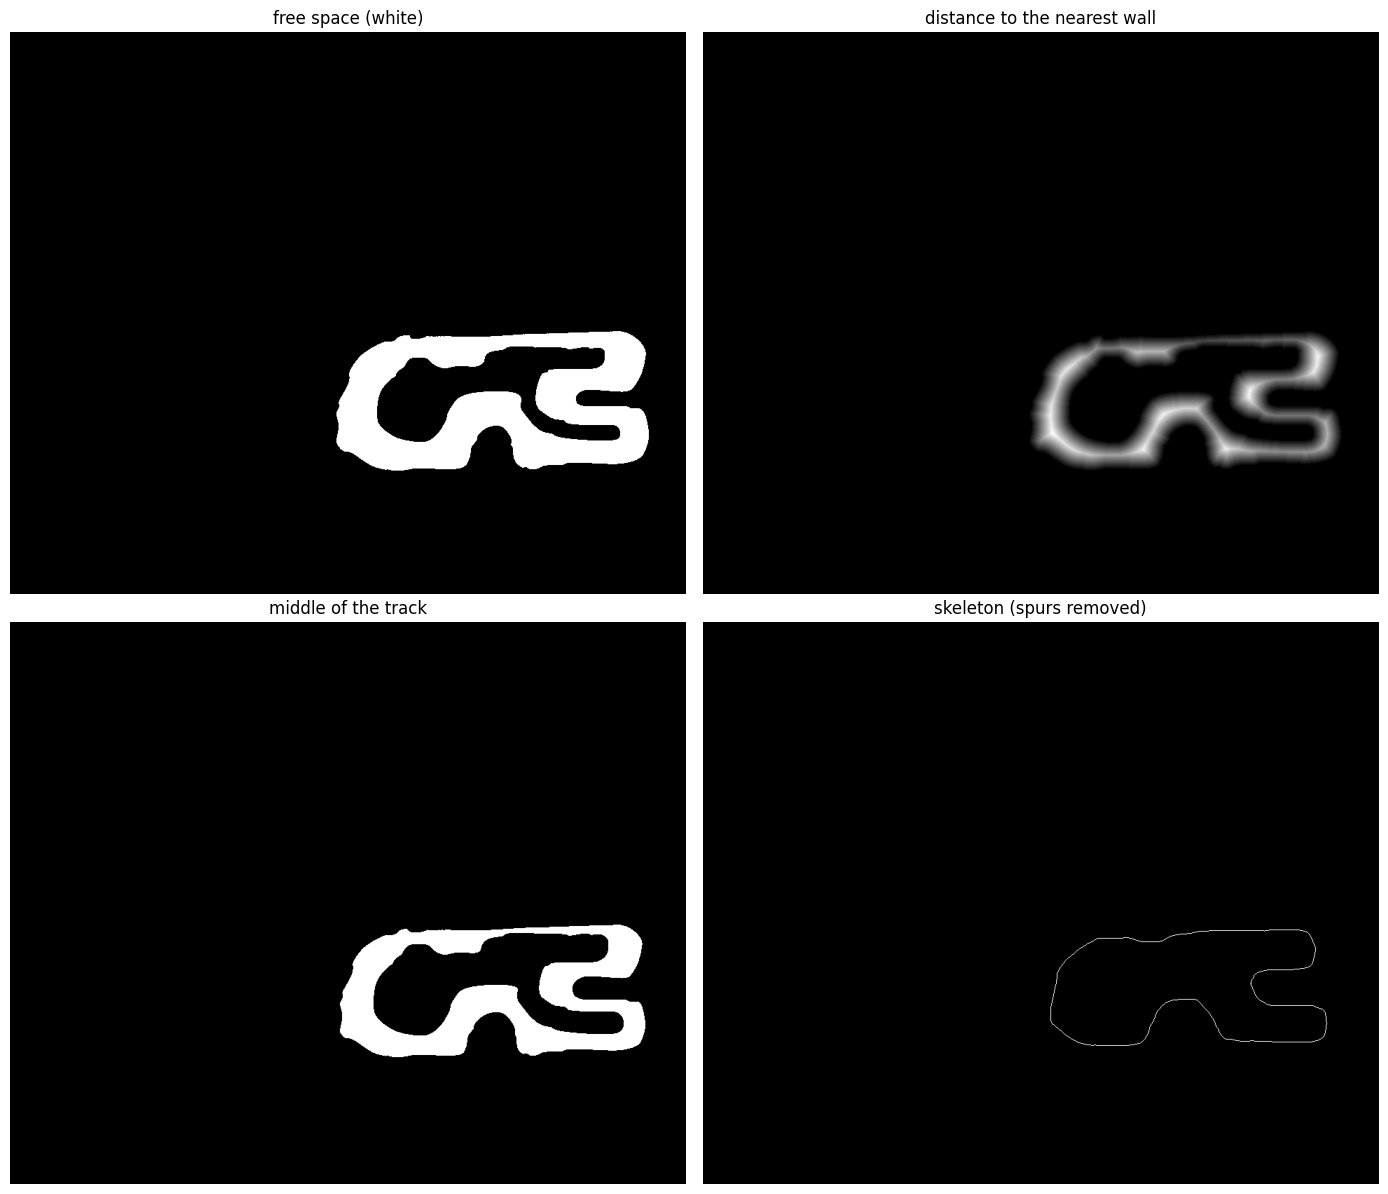

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, key, title in zip(axes.flat, ["binary", "dist", "centers", "skeleton"],
                          ["free space (white)", "distance to the nearest wall", "middle of the track", "skeleton (spurs removed)"]):
    ax.imshow(result[key], cmap="gray", origin="lower")
    ax.set_title(title); ax.axis("off")
fig.tight_layout()

### Step 3: the walk around the loop (colour = order, green = start)

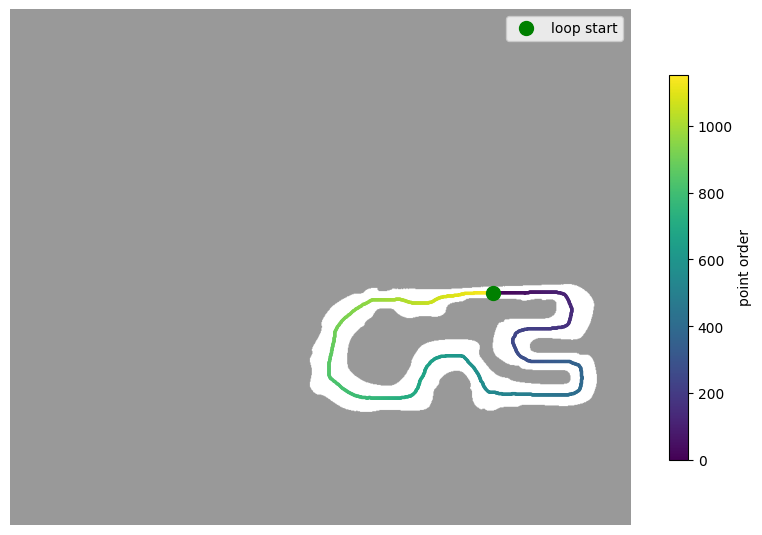

In [7]:
order = result["order_px"]
plt.figure(figsize=(10, 10))
plt.imshow(result["binary"], cmap="gray", origin="lower", alpha=0.4)
plt.scatter(order[:, 0], order[:, 1], c=np.arange(len(order)), s=2, cmap="viridis")
plt.plot(order[0, 0], order[0, 1], "go", ms=10, label="loop start")
plt.legend(); plt.axis("off"); plt.colorbar(shrink=0.5, label="point order")

### Step 4: raw centerline vs smoothed and resampled (metres)

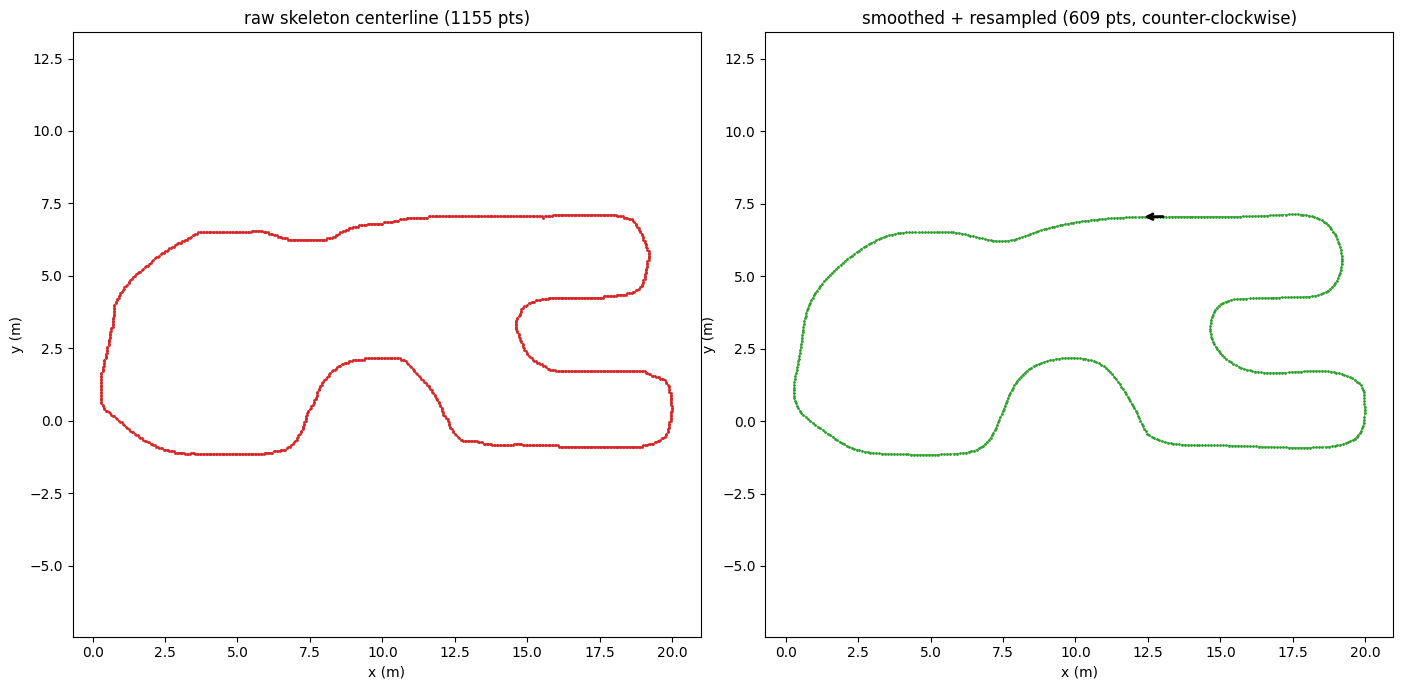

In [8]:
raw, xyw = result["raw"], result["xyw"]
fig, (axr, axs) = plt.subplots(1, 2, figsize=(14, 7))
axr.plot(raw[:, 0], raw[:, 1], ".-", ms=2, lw=0.5, color="tab:red"); axr.set_title(f"raw skeleton centerline ({len(raw)} pts)")
axs.plot(xyw[:, 0], xyw[:, 1], ".-", ms=2, lw=0.5, color="tab:green"); axs.set_title(f"smoothed + resampled ({len(xyw)} pts, counter-clockwise)")
for a in (axr, axs):
    a.set_aspect("equal", "datalim"); a.set_xlabel("x (m)"); a.set_ylabel("y (m)")
axs.annotate("", xy=xyw[8, :2], xytext=xyw[0, :2], arrowprops=dict(arrowstyle="->", color="k", lw=2))
fig.tight_layout()

In [9]:
centerline.write_csv(f"inputs/tracks/{MAP_NAME}.csv", result["xyw"])
print(f"wrote inputs/tracks/{MAP_NAME}.csv")

wrote inputs/tracks/e7_fifth_big_real_track.csv


Next: `sanity_check.ipynb` to see the centerline on the map, then the optimizer (`python main_globaltraj_f110.py --map_name <map> --direction ccw|cw`), or `python make_raceline.py <map>` for both directions, the report and the export in one go.